In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import re
import unicodedata

from pathlib import Path

from sklearn.linear_model import RidgeClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score
)

N_STATES = 5
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

In [2]:
DATA_DIR = Path("../Data")
RESULTS_DIR = Path("results")

RESULTS_DIR.mkdir(exist_ok=True)

print("Data folder exists:", DATA_DIR.exists())

if not DATA_DIR.exists():
    raise FileNotFoundError("Data folder not found.")

print("Feature files:", len(list(DATA_DIR.glob("*_features.csv"))))
print("Processed files:", len(list(DATA_DIR.glob("*_processed.csv"))))

Data folder exists: True
Feature files: 26
Processed files: 26


In [3]:
def clean_name(name):
    name = unicodedata.normalize("NFKC", name)

    name = "".join(
        char for char in name
        if unicodedata.category(char) != "Cf"
    )

    return name.strip().lower()


def get_recording_key(filepath):

    name = clean_name(filepath.stem)

    name = re.sub(
        r"_(features|processed)$",
        "",
        name
    )

    if name.startswith("abduct"):
        movement = "abduction"

    elif name.startswith("elevate"):
        movement = "elevating"

    elif name.startswith("flex"):
        movement = "flexing"

    elif name.startswith("sitting"):
        movement = "sitting"

    elif name.startswith("standing"):
        movement = "standing"

    elif name.startswith("walking"):
        movement = "walking"

    else:
        return None

    match = re.search(r"z\s*(\d+)", name)

    if match:
        trial = int(match.group(1))

    elif movement == "standing":
        trial = 1

    else:
        return None

    return movement, trial


feature_files = {}
processed_files = {}

for filepath in DATA_DIR.glob("*_features.csv"):
    key = get_recording_key(filepath)

    if key is not None:
        if key in feature_files:
            raise ValueError(f"Duplicate feature file: {key}")
        feature_files[key] = filepath


for filepath in DATA_DIR.glob("*_processed.csv"):
    key = get_recording_key(filepath)

    if key is not None:
        if key in processed_files:
            raise ValueError(f"Duplicate processed file: {key}")
        processed_files[key] = filepath


common_keys = sorted(
    set(feature_files) & set(processed_files)
)

print("Matched recordings:", len(common_keys))

print("\nMissing processed recordings:")
print(sorted(set(feature_files) - set(processed_files)))

print("\nMissing feature recordings:")
print(sorted(set(processed_files) - set(feature_files)))

if not common_keys:
    raise ValueError("No matching recordings found.")

Matched recordings: 26

Missing processed recordings:
[]

Missing feature recordings:
[]


In [4]:
standing_key = ("standing", 1)

if standing_key not in processed_files:
    raise FileNotFoundError(
        "Standing processed file is missing."
    )


def accel_tilt_deg(df, side):

    x = pd.to_numeric(
        df[f"Thigh_{side}_Accel_X"],
        errors="coerce"
    ).to_numpy(dtype=float)

    y = pd.to_numeric(
        df[f"Thigh_{side}_Accel_Y"],
        errors="coerce"
    ).to_numpy(dtype=float)

    z = pd.to_numeric(
        df[f"Thigh_{side}_Accel_Z"],
        errors="coerce"
    ).to_numpy(dtype=float)

    return np.degrees(
        np.arctan2(
            np.sqrt(x**2 + y**2),
            z
        )
    )


standing = pd.read_csv(
    processed_files[standing_key]
)

neutral_L = np.nanmedian(
    accel_tilt_deg(standing, "L")
)

neutral_R = np.nanmedian(
    accel_tilt_deg(standing, "R")
)

if not np.isfinite([neutral_L, neutral_R]).all():
    raise ValueError("Invalid standing reference.")

print("Left neutral:", neutral_L)
print("Right neutral:", neutral_R)

Left neutral: 101.62686114319813
Right neutral: 101.0616092669301


In [5]:
def normalize_score(values):

    values = np.array(
        values,
        dtype=float,
        copy=True
    )

    values[~np.isfinite(values)] = np.nan

    if np.all(np.isnan(values)):
        return np.full_like(values, np.nan)

    high = np.nanpercentile(values, 95)

    if not np.isfinite(high) or high <= 0:
        return np.full_like(values, np.nan)

    return np.clip(values / high, 0, 1)


def score_to_state(scores):

    scores = np.array(
        scores,
        dtype=float,
        copy=True
    )

    states = np.full(scores.shape, np.nan)

    valid = np.isfinite(scores)

    states[valid] = np.clip(
        np.floor(scores[valid] * N_STATES),
        0,
        N_STATES - 1
    )

    return states


def generate_states(processed):

    result = processed.copy()

    tilt_L = accel_tilt_deg(result, "L")
    tilt_R = accel_tilt_deg(result, "R")

    movement_L = np.abs(tilt_L - neutral_L)
    movement_R = np.abs(tilt_R - neutral_R)

    score_L = normalize_score(movement_L)
    score_R = normalize_score(movement_R)

    result["State_L"] = score_to_state(score_L)
    result["State_R"] = score_to_state(score_R)

    return result


print("State-generation functions ready.")

State-generation functions ready.


In [6]:
all_aligned = []
alignment_report = []

for key in common_keys:

    movement, trial = key

    features = pd.read_csv(feature_files[key])
    processed = pd.read_csv(processed_files[key])

    processed = generate_states(processed)

    processed["sample_index"] = pd.to_numeric(
        processed["sample_index"],
        errors="coerce"
    )

    processed = processed.dropna(
        subset=["sample_index"]
    ).sort_values("sample_index")

    sample_indices = processed["sample_index"].to_numpy()

    rows = []

    for _, row in features.iterrows():

        start = pd.to_numeric(
            row["start_sample_index"],
            errors="coerce"
        )

        end = pd.to_numeric(
            row["end_sample_index"],
            errors="coerce"
        )

        if not np.isfinite(start) or not np.isfinite(end):
            continue

        mask = (
            (sample_indices >= start)
            & (sample_indices <= end)
        )

        window = processed.loc[mask].dropna(
            subset=["State_L", "State_R"]
        )

        if window.empty:
            continue

        output = row.to_dict()

        output["State_L"] = int(
            window["State_L"].mode().iloc[0]
        )

        output["State_R"] = int(
            window["State_R"].mode().iloc[0]
        )

        output["movement"] = movement
        output["trial"] = trial
        output["recording_id"] = f"{movement}_z{trial}"

        rows.append(output)

    alignment_report.append({
        "Recording": f"{movement}_z{trial}",
        "Original Windows": len(features),
        "Aligned Windows": len(rows)
    })

    if rows:
        all_aligned.append(pd.DataFrame(rows))


if not all_aligned:
    raise ValueError("No aligned windows created.")

data = pd.concat(
    all_aligned,
    ignore_index=True
)

print("Aligned dataset:", data.shape)
print("Recordings:", data["recording_id"].nunique())

display(pd.DataFrame(alignment_report))

Aligned dataset: (2281, 58)
Recordings: 26


,Recording,Original Windows,Aligned Windows
0,abduction_z1,70,70
1,abduction_z2,56,56
2,abduction_z3,66,66
3,abduction_z4,72,72
4,abduction_z5,78,78
5,elevating_z1,120,120
6,elevating_z2,122,122
7,elevating_z3,99,99
8,elevating_z4,84,84
9,elevating_z5,95,95


In [7]:
FEATURE_SUFFIXES = (
    "_rms",
    "_mav",
    "_iemg",
    "_waveform_length",
    "_zero_crossings",
    "_slope_sign_changes"
)

feature_columns = [
    col for col in data.columns
    if col.endswith(FEATURE_SUFFIXES)
]

print("Number of features:", len(feature_columns))

if len(feature_columns) != 48:
    raise ValueError(
        f"Expected 48 features, found {len(feature_columns)}"
    )

data[feature_columns] = data[feature_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

data[feature_columns] = data[feature_columns].replace(
    [np.inf, -np.inf],
    np.nan
)

print("EMG features ready.")

Number of features: 48
EMG features ready.


In [8]:
# Standing is used for the neutral reference
model_data = data[
    data["movement"] != "standing"
].copy()

TRAIN_TRIALS = [1, 2, 3]
VAL_TRIALS = [4]
TEST_TRIALS = [5]

train_mask = model_data["trial"].isin(TRAIN_TRIALS)
val_mask = model_data["trial"].isin(VAL_TRIALS)
test_mask = model_data["trial"].isin(TEST_TRIALS)

X_train = model_data.loc[train_mask, feature_columns].copy()
X_val = model_data.loc[val_mask, feature_columns].copy()
X_test = model_data.loc[test_mask, feature_columns].copy()

y_train = model_data.loc[
    train_mask, ["State_L", "State_R"]
].copy()

y_val = model_data.loc[
    val_mask, ["State_L", "State_R"]
].copy()

y_test = model_data.loc[
    test_mask, ["State_L", "State_R"]
].copy()

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (1289, 48)
Validation: (408, 48)
Testing: (422, 48)


In [9]:
train_ids = set(model_data.loc[train_mask, "recording_id"])
val_ids = set(model_data.loc[val_mask, "recording_id"])
test_ids = set(model_data.loc[test_mask, "recording_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(X_train) > 0
assert len(X_val) > 0
assert len(X_test) > 0

assert y_train.notna().all().all()
assert y_val.notna().all().all()
assert y_test.notna().all().all()

print("Training recordings:", len(train_ids))
print("Validation recordings:", len(val_ids))
print("Testing recordings:", len(test_ids))

print("\nTraining state distribution:")

print("Left:")
print(y_train["State_L"].value_counts().sort_index())

print("\nRight:")
print(y_train["State_R"].value_counts().sort_index())

print("\nData verification completed.")

Training recordings: 15
Validation recordings: 5
Testing recordings: 5

Training state distribution:
Left:
State_L
0    395
1    231
2    238
3    182
4    243
Name: count, dtype: int64

Right:
State_R
0    774
1     85
2     56
3    103
4    271
Name: count, dtype: int64

Data verification completed.


In [10]:
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

from tensorflow.keras import Model, Input
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

In [11]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    imputer.fit_transform(X_train)
)

X_val_scaled = scaler.transform(
    imputer.transform(X_val)
)

X_test_scaled = scaler.transform(
    imputer.transform(X_test)
)

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Training: (1289, 48)
Validation: (408, 48)
Testing: (422, 48)


In [12]:
SEQUENCE_LENGTH = 5

def create_sequences(X, y, recording_ids, times):

    X_seq = []
    y_seq = []
    seq_ids = []
    seq_times = []

    for recording in np.unique(recording_ids):

        indices = np.where(recording_ids == recording)[0]

        # Sort the recording's windows by time
        indices = indices[np.argsort(times[indices])]

        for i in range(SEQUENCE_LENGTH - 1, len(indices)):

            selected = indices[
                i - SEQUENCE_LENGTH + 1 : i + 1
            ]

            X_seq.append(X[selected])

            # Label corresponds to the final window
            y_seq.append(y[selected[-1]])

            seq_ids.append(recording)
            seq_times.append(times[selected[-1]])

    return (
        np.asarray(X_seq, dtype=np.float32),
        np.asarray(y_seq, dtype=np.int32),
        np.asarray(seq_ids),
        np.asarray(seq_times)
    )

In [13]:
def prepare_sequences(X_scaled, y, mask):

    recording_ids = model_data.loc[
        mask, "recording_id"
    ].to_numpy()

    times = model_data.loc[
        mask, "end_time_s"
    ].to_numpy()

    return create_sequences(
        X_scaled,
        y.to_numpy(),
        recording_ids,
        times
    )


X_train_seq, y_train_seq, train_ids, train_times = prepare_sequences(
    X_train_scaled, y_train, train_mask
)

X_val_seq, y_val_seq, val_ids, val_times = prepare_sequences(
    X_val_scaled, y_val, val_mask
)

X_test_seq, y_test_seq, test_ids, test_times = prepare_sequences(
    X_test_scaled, y_test, test_mask
)

print("Training sequences:", X_train_seq.shape)
print("Validation sequences:", X_val_seq.shape)
print("Testing sequences:", X_test_seq.shape)

assert len(X_train_seq) > 0
assert len(X_val_seq) > 0
assert len(X_test_seq) > 0

Training sequences: (1229, 5, 48)
Validation sequences: (388, 5, 48)
Testing sequences: (402, 5, 48)


In [14]:
def build_rnn(units=32, dropout=0.3):

    inputs = Input(
        shape=(SEQUENCE_LENGTH, len(feature_columns))
    )

    x = LSTM(units)(inputs)

    x = Dropout(dropout)(x)

    x = Dense(16, activation="relu")(x)

    left_output = Dense(
        N_STATES,
        activation="softmax",
        name="left_state"
    )(x)

    right_output = Dense(
        N_STATES,
        activation="softmax",
        name="right_state"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=[left_output, right_output]
    )

    model.compile(
        optimizer="adam",
        loss={
            "left_state": "sparse_categorical_crossentropy",
            "right_state": "sparse_categorical_crossentropy"
        },
        metrics={
            "left_state": ["accuracy"],
            "right_state": ["accuracy"]
        }
    )

    return model


rnn_model = build_rnn()

rnn_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 5, 48)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │     10,368 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        528 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ left_state (Dense)  │ (None, 5)         │         85 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ right_state (Dense) │ (None, 5)         │         85 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,066 (43.23 KB)

 Trainable params: 11,066 (43.23 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
def calculate_average_macro_f1(y_true, pred_L, pred_R):

    f1_L = f1_score(
        y_true[:, 0],
        pred_L,
        labels=range(N_STATES),
        average="macro",
        zero_division=0
    )

    f1_R = f1_score(
        y_true[:, 1],
        pred_R,
        labels=range(N_STATES),
        average="macro",
        zero_division=0
    )

    return (f1_L + f1_R) / 2

In [16]:
configurations = [
    {"units": 16, "dropout": 0.3},
    {"units": 32, "dropout": 0.3}
]

tuning_results = []

best_f1 = -1
best_model = None
best_config = None
best_history = None

for config in configurations:

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_rnn(
        units=config["units"],
        dropout=config["dropout"]
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_seq,
        {
            "left_state": y_train_seq[:, 0],
            "right_state": y_train_seq[:, 1]
        },
        validation_data=(
            X_val_seq,
            {
                "left_state": y_val_seq[:, 0],
                "right_state": y_val_seq[:, 1]
            }
        ),
        epochs=100,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    prob_L, prob_R = model.predict(
        X_val_seq,
        verbose=0
    )

    pred_L = np.argmax(prob_L, axis=1)
    pred_R = np.argmax(prob_R, axis=1)

    average_f1 = calculate_average_macro_f1(
        y_val_seq,
        pred_L,
        pred_R
    )

    tuning_results.append({
        "LSTM Units": config["units"],
        "Dropout": config["dropout"],
        "Validation Macro F1": average_f1
    })

    print(
        f"Units: {config['units']} | "
        f"Validation Macro F1: {average_f1:.4f}"
    )

    if average_f1 > best_f1:
        best_f1 = average_f1
        best_model = model
        best_config = config.copy()
        best_history = history

rnn_tuning = pd.DataFrame(tuning_results)

display(rnn_tuning)

rnn_model = best_model

print("\nSelected configuration:", best_config)

Units: 16 | Validation Macro F1: 0.5193
Units: 32 | Validation Macro F1: 0.5205


,LSTM Units,Dropout,Validation Macro F1
0,16,0.3,0.519276
1,32,0.3,0.520482



Selected configuration: {'units': 32, 'dropout': 0.3}


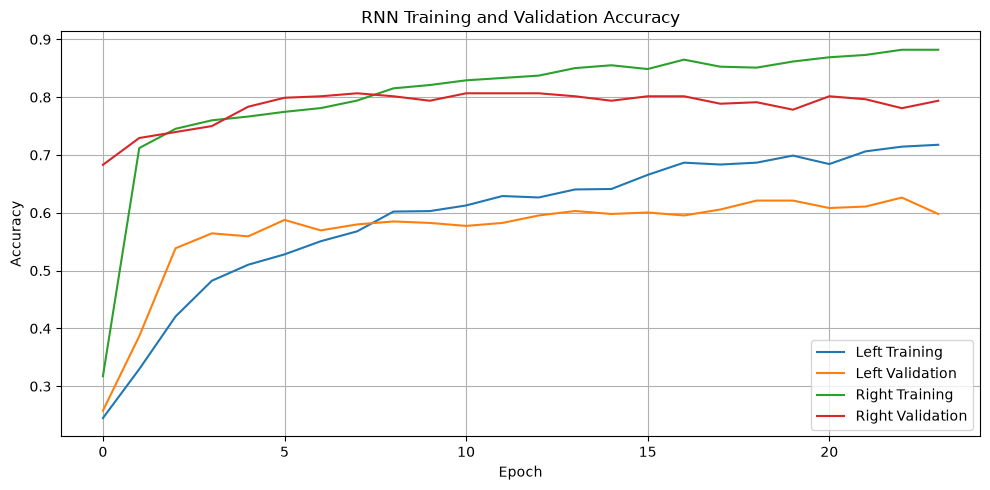

In [17]:
history = best_history

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["left_state_accuracy"],
    label="Left Training"
)

plt.plot(
    history.history["val_left_state_accuracy"],
    label="Left Validation"
)

plt.plot(
    history.history["right_state_accuracy"],
    label="Right Training"
)

plt.plot(
    history.history["val_right_state_accuracy"],
    label="Right Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
prob_L, prob_R = rnn_model.predict(
    X_test_seq,
    verbose=0
)

pred_L = np.argmax(prob_L, axis=1)
pred_R = np.argmax(prob_R, axis=1)

print("First 10 RNN predictions:\n")

for left, right in zip(pred_L[:10], pred_R[:10]):

    print(
        f"Left: S{left} | "
        f"Right: S{right} | "
        f"Bilateral: L{left}_R{right}"
    )

First 10 RNN predictions:

Left: S2 | Right: S1 | Bilateral: L2_R1
Left: S2 | Right: S3 | Bilateral: L2_R3
Left: S1 | Right: S1 | Bilateral: L1_R1
Left: S1 | Right: S1 | Bilateral: L1_R1
Left: S1 | Right: S3 | Bilateral: L1_R3
Left: S2 | Right: S3 | Bilateral: L2_R3
Left: S2 | Right: S3 | Bilateral: L2_R3
Left: S1 | Right: S3 | Bilateral: L1_R3
Left: S1 | Right: S3 | Bilateral: L1_R3
Left: S1 | Right: S4 | Bilateral: L1_R4


In [19]:
f1_left = f1_score(
    y_test_seq[:, 0],
    pred_L,
    labels=range(N_STATES),
    average="macro",
    zero_division=0
)

f1_right = f1_score(
    y_test_seq[:, 1],
    pred_R,
    labels=range(N_STATES),
    average="macro",
    zero_division=0
)

f1_average = (f1_left + f1_right) / 2

print("RNN CLASSIFIER - F1 SCORES\n")

print(f"Left-leg Macro F1:  {f1_left:.4f}")
print(f"Right-leg Macro F1: {f1_right:.4f}")
print(f"Average Macro F1:   {f1_average:.4f}")

RNN CLASSIFIER - F1 SCORES

Left-leg Macro F1:  0.4799
Right-leg Macro F1: 0.5375
Average Macro F1:   0.5087


In [20]:
accuracy_L = accuracy_score(
    y_test_seq[:, 0],
    pred_L
)

accuracy_R = accuracy_score(
    y_test_seq[:, 1],
    pred_R
)

bilateral_accuracy = np.mean(
    (pred_L == y_test_seq[:, 0])
    &
    (pred_R == y_test_seq[:, 1])
)

print("RNN CLASSIFIER - ACCURACY\n")

print(f"Left-leg Accuracy:  {accuracy_L * 100:.2f}%")
print(f"Right-leg Accuracy: {accuracy_R * 100:.2f}%")
print(f"Bilateral Accuracy: {bilateral_accuracy * 100:.2f}%")

RNN CLASSIFIER - ACCURACY

Left-leg Accuracy:  57.96%
Right-leg Accuracy: 80.85%
Bilateral Accuracy: 54.23%


In [21]:
print("Predicted left-leg states:")
print(np.unique(pred_L))

print("\nPredicted right-leg states:")
print(np.unique(pred_R))

print("\nLeft-leg prediction distribution:")
print(pd.Series(pred_L).value_counts().sort_index())

print("\nRight-leg prediction distribution:")
print(pd.Series(pred_R).value_counts().sort_index())

Predicted left-leg states:
[0 1 2 3 4]

Predicted right-leg states:
[0 1 2 3 4]

Left-leg prediction distribution:
0    163
1     60
2     52
3     35
4     92
Name: count, dtype: int64

Right-leg prediction distribution:
0    263
1     17
2     14
3     18
4     90
Name: count, dtype: int64


In [22]:
print("LEFT LEG CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test_seq[:, 0],
        pred_L,
        labels=range(N_STATES),
        target_names=[f"S{i}" for i in range(N_STATES)],
        zero_division=0
    )
)

print("\nRIGHT LEG CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test_seq[:, 1],
        pred_R,
        labels=range(N_STATES),
        target_names=[f"S{i}" for i in range(N_STATES)],
        zero_division=0
    )
)

LEFT LEG CLASSIFICATION REPORT

              precision    recall  f1-score   support

          S0       0.74      0.65      0.69       187
          S1       0.22      0.36      0.27        36
          S2       0.12      0.17      0.14        36
          S3       0.71      0.40      0.51        63
          S4       0.74      0.85      0.79        80

    accuracy                           0.58       402
   macro avg       0.51      0.48      0.48       402
weighted avg       0.63      0.58      0.60       402


RIGHT LEG CLASSIFICATION REPORT

              precision    recall  f1-score   support

          S0       0.88      0.95      0.91       243
          S1       0.41      0.23      0.29        31
          S2       0.57      0.31      0.40        26
          S3       0.22      0.17      0.20        23
          S4       0.83      0.95      0.89        79

    accuracy                           0.81       402
   macro avg       0.58      0.52      0.54       402
weighted av

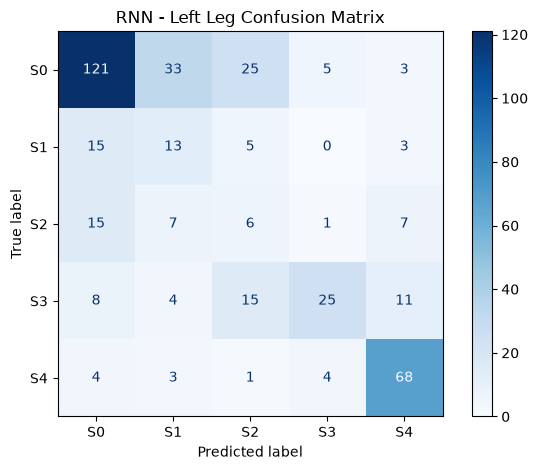

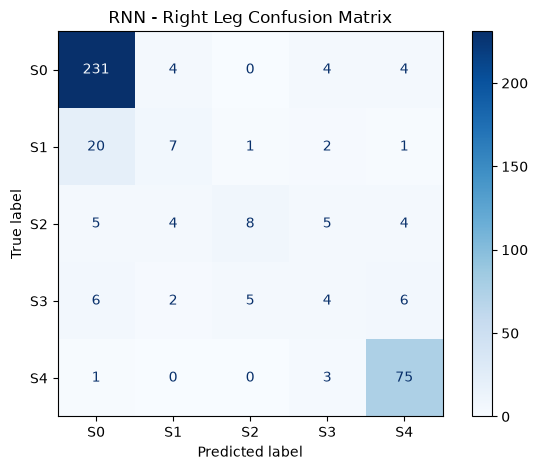

In [23]:
for side, actual, predicted in [
    ("Left", y_test_seq[:, 0], pred_L),
    ("Right", y_test_seq[:, 1], pred_R)
]:

    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        labels=range(N_STATES),
        display_labels=[f"S{i}" for i in range(N_STATES)],
        cmap="Blues"
    )

    plt.title(f"RNN - {side} Leg Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [24]:
test_results = pd.DataFrame({
    "Time_s": test_times,
    "recording_id": test_ids,

    "ActualState_L": y_test_seq[:, 0],
    "ActualState_R": y_test_seq[:, 1],

    "CandidateState_L": pred_L,
    "CandidateState_R": pred_R
})

test_results["BilateralState"] = (
    "L"
    + test_results["CandidateState_L"].astype(str)
    + "_R"
    + test_results["CandidateState_R"].astype(str)
)

print("RNN predictions:")

display(test_results.groupby("recording_id").head(5))

RNN predictions:


,Time_s,recording_id,ActualState_L,ActualState_R,CandidateState_L,CandidateState_R,BilateralState
0,0.5994,abduction_z5,0,0,2,1,L2_R1
1,0.6994,abduction_z5,0,0,2,3,L2_R3
2,0.7994,abduction_z5,0,1,1,1,L1_R1
3,0.8993,abduction_z5,0,1,1,1,L1_R1
4,0.9993,abduction_z5,0,2,1,3,L1_R3
74,0.5994,elevating_z5,2,0,2,1,L2_R1
75,0.6994,elevating_z5,3,0,2,3,L2_R3
76,0.7994,elevating_z5,3,1,2,3,L2_R3
77,0.8993,elevating_z5,3,1,2,3,L2_R3
78,0.9993,elevating_z5,3,2,2,3,L2_R3


In [25]:
MAX_STATE_JUMP = 3

test_results["AcceptedState_L"] = 0
test_results["AcceptedState_R"] = 0
test_results["FaultFlag"] = False

for recording_id, group in test_results.groupby(
    "recording_id",
    sort=False
):

    prev_L = None
    prev_R = None

    group = group.sort_values("Time_s")

    for index, row in group.iterrows():

        cand_L = int(row["CandidateState_L"])
        cand_R = int(row["CandidateState_R"])

        if prev_L is None:

            prev_L = cand_L
            prev_R = cand_R
            fault = False

        else:

            fault = (
                abs(cand_L - prev_L) > MAX_STATE_JUMP
                or
                abs(cand_R - prev_R) > MAX_STATE_JUMP
            )

            if not fault:
                prev_L = cand_L
                prev_R = cand_R

        test_results.loc[index, "AcceptedState_L"] = prev_L
        test_results.loc[index, "AcceptedState_R"] = prev_R
        test_results.loc[index, "FaultFlag"] = fault

print("Rejected transitions:", test_results["FaultFlag"].sum())

Rejected transitions: 100


In [26]:
def state_to_motor_command(state):
    return state / (N_STATES - 1)


test_results["MotorCommand_L"] = (
    test_results["AcceptedState_L"]
    .apply(state_to_motor_command)
)

test_results["MotorCommand_R"] = (
    test_results["AcceptedState_R"]
    .apply(state_to_motor_command)
)

display(test_results.head(10))

,Time_s,recording_id,ActualState_L,ActualState_R,CandidateState_L,CandidateState_R,BilateralState,AcceptedState_L,AcceptedState_R,FaultFlag,MotorCommand_L,MotorCommand_R
0,0.5994,abduction_z5,0,0,2,1,L2_R1,2,1,False,0.50,0.25
1,0.6994,abduction_z5,0,0,2,3,L2_R3,2,3,False,0.50,0.75
2,0.7994,abduction_z5,0,1,1,1,L1_R1,1,1,False,0.25,0.25
3,0.8993,abduction_z5,0,1,1,1,L1_R1,1,1,False,0.25,0.25
4,0.9993,abduction_z5,0,2,1,3,L1_R3,1,3,False,0.25,0.75
5,1.0993,abduction_z5,0,3,2,3,L2_R3,2,3,False,0.50,0.75
6,1.1993,abduction_z5,0,3,2,3,L2_R3,2,3,False,0.50,0.75
7,1.2993,abduction_z5,0,4,1,3,L1_R3,1,3,False,0.25,0.75
8,1.3993,abduction_z5,0,4,1,3,L1_R3,1,3,False,0.25,0.75
9,1.4992,abduction_z5,0,4,1,4,L1_R4,1,4,False,0.25,1.00
